# Aula 06 · Vídeo 2 — Drift Detection: Data, Concept, Prompt e Response

> **Disciplina:** Segurança, Guardrails e Conformidade para LLMs · **Caso condutor:** Banco **Aurora** / **Aurora Assist**
> **Tipo:** conceitual **+** prático · **Doc 04:** §"O que é drift" e §"Detecção estatística de drift" (Tabela 2, Figura 2)

## 🎯 Objetivos
- Distinguir os **quatro tipos de drift** (data, concept, prompt, response).
- Aplicar **KS, PSI, MMD e Wasserstein** (NumPy puro) sobre tráfego sintético do Aurora Assist.
- Fazer a **leitura integrada**: um sinal isolado = investigar; múltiplos = incidente.

> [!WARNING]
> ⚠️ **Uso ético.** Todo o tráfego é sintético; uso **defensivo e didático** (Doc 04).

## 1. Teoria (Doc 04, §"O que é drift")

> *"Drift é a mudança nas distribuições dos dados ao longo do tempo. O efeito é uma degradação silenciosa: as respostas pioram gradualmente, sem qualquer erro explícito."* — Doc 04

Quatro tipos, cada um com sua assinatura (Figura 2):
- **Data drift** — a distribuição das entradas muda: $P_t(X) \neq P_0(X)$.
- **Concept drift** — a relação entrada→resposta muda: $P_t(Y\mid X) \neq P_0(Y\mid X)$.
- **Prompt drift** — muda *como* os usuários escrevem (formal → casual).
- **Response drift** — a qualidade das saídas degrada ao longo do tempo.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
print('ROOT =', ROOT)

ROOT = E:\Personal\08_Projects-Code-Repos\9mlet-llm-security\aula06_governanca_monitoramento


In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt

from src.security.drift import (
    ks_2samp, psi, mmd2_rbf, mmd_permutation_test, wasserstein_1d,
    embed_matrix, detect_prompt_drift, DriftDetector,
)
from src.security.schemas import DriftMethod

rng = np.random.default_rng(42)  # seed fixa -> reprodutível

## 2. KS — Kolmogorov-Smirnov (Doc 04, Snippet 2)

O teste KS compara duas distribuições pela **maior diferença entre as CDFs**, $D = \sup_x |F_{\text{ref}}(x) - F_{\text{now}}(x)|$. Se $p < 0{,}05$, rejeitamos a hipótese de que são iguais.

KS: D=0.623  p=0.00000  -> drift? True


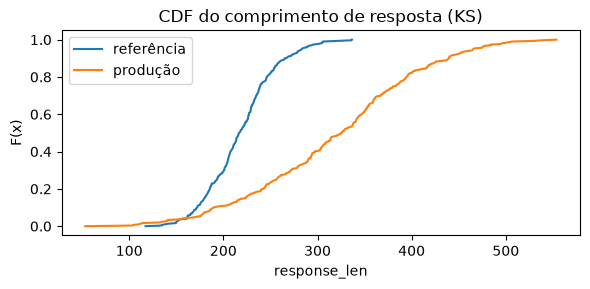

In [3]:
# Referência: comprimento de respostas na janela baseline; produção: mais longas.
ref_len = rng.normal(220, 40, 300)
now_len = rng.normal(320, 90, 300)
D, p = ks_2samp(ref_len, now_len)
print(f'KS: D={D:.3f}  p={p:.5f}  -> drift? {p < 0.05}')

# CDFs empíricas
xs = np.sort(np.concatenate([ref_len, now_len]))
plt.figure(figsize=(6, 3))
plt.plot(np.sort(ref_len), np.linspace(0, 1, ref_len.size), label='referência')
plt.plot(np.sort(now_len), np.linspace(0, 1, now_len.size), label='produção')
plt.title('CDF do comprimento de resposta (KS)'); plt.xlabel('response_len'); plt.ylabel('F(x)')
plt.legend(); plt.tight_layout(); plt.show()

## 3. PSI — Population Stability Index (Doc 04)

Muito usado em crédito, quantiza em faixas: $\text{PSI} = \sum_i (Q_i - P_i)\,\ln(Q_i/P_i)$. Convenção do setor: **>0,25 = deriva severa**; 0,10–0,25 = moderada.

In [4]:
ref_lat = rng.normal(800, 150, 400)
now_lat = rng.normal(1300, 400, 400)
value = psi(ref_lat, now_lat, bins=10)
faixa = 'SEVERA' if value >= 0.25 else 'moderada' if value >= 0.10 else 'estável'
print(f'PSI(latência) = {value:.3f}  -> {faixa}')

PSI(latência) = 2.505  -> SEVERA


## 4. MMD — Maximum Mean Discrepancy sobre embeddings (Doc 04, Snippet 1)

Para alta dimensão (embeddings de prompts), o **MMD** com kernel RBF mede a distância entre distribuições:

$$\text{MMD}^2 = \tfrac{1}{m^2}\sum k(x_i,x_j) + \tfrac{1}{n^2}\sum k(y_i,y_j) - \tfrac{2}{mn}\sum k(x_i,y_j).$$

Aqui capturamos o **prompt drift**: os clientes começam a perguntar de novos produtos e em estilo casual.

typical vs typical : MMD²=0.0000  p=0.995
typical vs novos   : MMD²=0.2293  p=0.134


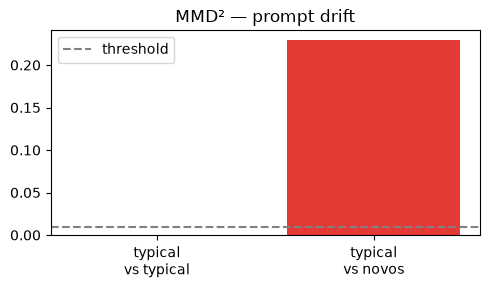

In [5]:
typical = [
    'Qual a taxa do CDB do Aurora?', 'Como emito um boleto?', 'Horário da agência central?',
    'Quais as tarifas do pacote?', 'Como simulo um empréstimo?', 'Limite do cartão de crédito?',
    'Como abrir uma conta?', 'Rendimento da poupança?',
]
new_topics = [
    'compro bitcoin no aurora cripto app', 'pix parcelado novo como funciona',
    'cashback do cartao black quanto rende', 'tem staking de cripto ai',
    'portabilidade de salario open finance', 'buy now pay later cobra juros',
    'aurora cripto taxa de custodia', 'antecipar fgts pelo app novo',
]

X_ref = embed_matrix(typical)
X_new = embed_matrix(new_topics)
mmd_same, p_same = mmd_permutation_test(X_ref, embed_matrix(list(reversed(typical))), n_perm=200)
mmd_diff, p_diff = mmd_permutation_test(X_ref, X_new, n_perm=200)
print(f'typical vs typical : MMD²={mmd_same:.4f}  p={p_same:.3f}')
print(f'typical vs novos   : MMD²={mmd_diff:.4f}  p={p_diff:.3f}')

plt.figure(figsize=(5, 3))
plt.bar(['typical\nvs typical', 'typical\nvs novos'], [mmd_same, mmd_diff], color=['#4caf50', '#e53935'])
plt.axhline(0.010, ls='--', color='gray', label='threshold')
plt.title('MMD² — prompt drift'); plt.legend(); plt.tight_layout(); plt.show()

## 5. Wasserstein — deslocamentos graduais (Doc 04)

A distância de **Wasserstein** mede o "esforço" para transformar uma distribuição na outra — robusta a deslocamentos de massa. Aqui, a **groundedness** degrada (response drift).

Wasserstein(groundedness) = 0.233  -> drift? True


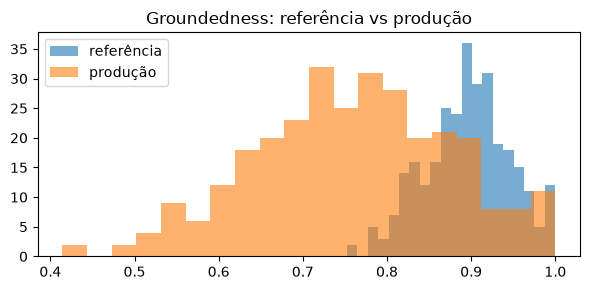

In [6]:
ref_g = rng.normal(0.90, 0.05, 300).clip(0, 1)
now_g = rng.normal(0.78, 0.12, 300).clip(0, 1)
w = wasserstein_1d(ref_g, now_g)
print(f'Wasserstein(groundedness) = {w:.3f}  -> drift? {w >= 0.15}')

plt.figure(figsize=(6, 3))
plt.hist(ref_g, bins=20, alpha=0.6, label='referência')
plt.hist(now_g, bins=20, alpha=0.6, label='produção')
plt.title('Groundedness: referência vs produção'); plt.legend(); plt.tight_layout(); plt.show()

## 6. Leitura integrada (Doc 04)

> *"Um valor-p baixo ou um MMD elevado não significam, isoladamente, que o sistema deve ser desligado. Eles indicam que o comportamento atual merece investigação."*

Combinamos os quatro sinais sobre o tráfego (referência × produção). Múltiplos sinais convergentes ⇒ **incidente**.

In [7]:
# Carrega o tráfego real (gerado por `uv run task seed-data`); se ausente, sintetiza.
def load(path):
    rows = [json.loads(l) for l in Path(path).read_text(encoding='utf-8').splitlines() if l]
    return {
        'prompts': [r['prompt'] for r in rows],
        'latency_ms': [r['latency_ms'] for r in rows],
        'response_len': [r['response_len'] for r in rows],
        'groundedness': [r['groundedness'] for r in rows],
    }

try:
    ref = load('data/traffic/reference.jsonl'); now = load('data/traffic/production.jsonl')
    print('Tráfego carregado:', len(ref['prompts']), 'ref /', len(now['prompts']), 'prod')
except FileNotFoundError:
    print('Tráfego não encontrado — rode `uv run task seed-data`. Usando sintético.')
    ref = {'prompts': typical, 'latency_ms': ref_lat, 'response_len': ref_len, 'groundedness': ref_g}
    now = {'prompts': new_topics, 'latency_ms': now_lat, 'response_len': now_len, 'groundedness': now_g}

Tráfego carregado: 200 ref / 200 prod


In [8]:
detector = DriftDetector()
results = [
    detector.prompt_drift(ref['prompts'], now['prompts']),
    detector.response_drift(ref['response_len'], now['response_len'], method=DriftMethod.KS),
    detector.response_drift(ref['groundedness'], now['groundedness']),
    detector.credit_stability(ref['latency_ms'], now['latency_ms']),
]
print(f"{'método':12s} {'tipo':16s} {'stat':>8s}  drift  severidade")
for r in results:
    print(f'{r.method.value:12s} {r.drift_type.value:16s} {r.statistic:8.4f}  {str(r.drifted):5s}  {r.severity.value}')

assessment = detector.assess(results)
print('\nDecisão integrada:', assessment['decision'].upper(),
      '| sinais convergentes:', assessment['converging_signals'])

método       tipo                 stat  drift  severidade
mmd          prompt_drift       0.0439  True   severe
ks           response_drift     0.6700  True   severe
wasserstein  response_drift     0.2245  True   moderate
psi          data_drift         2.3379  True   severe

Decisão integrada: INCIDENT | sinais convergentes: 4


## 7. (Opcional) Cross-validação com scipy/scikit-learn

O grupo `stats` (`uv sync --group stats`) permite conferir os resultados com implementações de referência (mesmo raciocínio do Doc 04, que usa `scipy.stats.ks_2samp` e `sklearn.metrics.pairwise.rbf_kernel`).

In [9]:
try:
    from scipy.stats import ks_2samp as sp_ks
    from scipy.stats import wasserstein_distance as sp_w
    d_sp, p_sp = sp_ks(ref_len, now_len)
    print(f'scipy KS : D={d_sp:.3f} p={p_sp:.5f}  (repo: D={D:.3f} p={p:.5f})')
    print(f'scipy W  : {sp_w(ref_g, now_g):.3f}  (repo normaliza; ordem preservada)')
except ImportError:
    print('scipy/sklearn não instalados. Rode: uv sync --group stats')

scipy/sklearn não instalados. Rode: uv sync --group stats


## ✅ Resumo e gancho

Detectamos **data/response drift** (KS, PSI, Wasserstein) e **prompt drift** (MMD) sobre o tráfego do Aurora Assist, e transformamos os sinais em uma **decisão de governança** (observar × incidente). No **Vídeo 3**, vamos instrumentar cada chamada com **OpenTelemetry gen_ai.*** e ver tokens, latência e custo por step.